# Практика 4. Как разлить компот за минимум подъёмов

Бабушка разлила компот по четырём стаканам. Обучим агента выравнивать объёмы двумя табличными методами обучения с подкреплением, SARSA и Q-learning. За один подъём можно разлить компот из одного стакана сразу в несколько других.



## 1. На какие вопросы ответить до программирования?

| Вопрос | Решение для эксперимента |
|---|---|
| Как измерять объём и учитывать вместимость? | Единица равна 50 мл. Всего 600 мл, каждый из четырёх стаканов вмещает 250 мл. Компот сохраняется, поэтому цель — 150 мл в каждом стакане. |
| Какими числами определяется состояние? | Упорядоченная четвёрка целых объёмов $(v_1,v_2,v_3,v_4)$ в единицах по 50 мл. Номер стакана определяется позицией в четвёрке. |
| Сколько состояний и откуда начинается эпизод? | 125 состояний с $0\le v_i\le5$ и $\sum_i v_i=12$ (объем компота общий в единицах агента). Старт равномерно выбирается из 124 неравных раскладов. |
| Что является одним дискретным действием? | Выбрать один стакан-источник и указать целые объёмы для трёх остальных. Можно разлить в один, два или три стакана за один подъём. |
| Когда действие доступно? | Переливаемый объём больше нуля и не превышает объёма в источнике. Ни один получатель не переполняется. Среда отдаёт маску доступных действий. |
| Как устроена награда? | $-1$ рубль за каждый подъём, включая последний. Дополнительных штрафов и бонусов нет. |
| Когда заканчивается эпизод? | При выравнивании объёмов (`terminated`). Лимит в 30 подъёмов останавливает слишком долгий эпизод (`truncated`). |
| Как сравнивать методы? | Одинаковые параметры, бюджет эпизодов и последовательности стартов. Сравниваем награду во время обучения, долю успешных решений и долю решений за минимальное число подъёмов. |

До учёта вместимости число неотрицательных четвёрок с суммой 12 равно $\binom{15}{3}$. Для каждого стакана исключаем случаи с объёмом от 6 и возвращаем случаи с двумя такими стаканами. Получаем $\binom{15}{3}-4\binom{9}{3}+\binom{4}{2}=125$.

Для каждого источника есть $\binom{8}{3}-1=55$ распределений с положительной суммой до проверки текущего расклада. Всего в `Discrete` 220 идентификаторов. Агент выбирает только доступные в текущем состоянии идентификаторы. При $\gamma=1$ суммарная награда за эпизод равна числу подъёмов со знаком минус.

In [1]:
from itertools import product
from math import comb

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Markdown, display
from matplotlib.animation import FuncAnimation

GLASSES = 4
UNIT_ML = 50
CAPACITY = 5
TOTAL = 12
TARGET = TOTAL // GLASSES
MAX_LIFTS = 30

STATES = np.array([
    volumes
    for volumes in product(range(CAPACITY + 1), repeat=GLASSES)
    if sum(volumes) == TOTAL
])
STATE_IDS = {tuple(volumes): i for i, volumes in enumerate(STATES)}
GOAL_ID = STATE_IDS[(TARGET,) * GLASSES]
START_IDS = np.flatnonzero(np.arange(len(STATES)) != GOAL_ID)

ACTIONS = []
deltas = []
for source in range(GLASSES):
    recipients = [i for i in range(GLASSES) if i != source]
    for portions in product(range(CAPACITY + 1), repeat=GLASSES - 1):
        if 0 < sum(portions) <= CAPACITY:
            delta = np.zeros(GLASSES, dtype=int)
            delta[source] = -sum(portions)
            delta[recipients] = portions
            ACTIONS.append((source, tuple(zip(recipients, portions))))
            deltas.append(delta)
DELTAS = np.array(deltas)

# Таблица переходов среды. Значение -1 обозначает недоступное действие.
next_volumes = STATES[:, None, :] + DELTAS[None, :, :]
feasible = ((next_volumes >= 0) & (next_volumes <= CAPACITY)).all(axis=2)
feasible[GOAL_ID] = False
TRANSITIONS = np.full(feasible.shape, -1, dtype=int)
TRANSITIONS[feasible] = [STATE_IDS[tuple(volumes)] for volumes in next_volumes[feasible]]
ACTION_MASKS = feasible.astype(np.int8)

assert len(STATES) == comb(15, 3) - 4 * comb(9, 3) + comb(4, 2) == 125
assert len(ACTIONS) == GLASSES * (comb(8, 3) - 1) == 220
assert ACTION_MASKS[START_IDS].any(axis=1).all()
print(f"Состояний: {len(STATES)}, стартовых: {len(START_IDS)}, действий: {len(ACTIONS)}")

Состояний: 125, стартовых: 124, действий: 220


## 2. Среда Gymnasium и точный минимум

`reset()` возвращает объёмы и маску, `step()` применяет выбранное переливание. `TimeLimit` задаёт предел эпизода, а `RecordEpisodeStatistics` записывает его суммарную награду и длину в `info["episode"]`.

Каждый стакан с начальным объёмом выше 150 мл нужно поднять хотя бы раз, потому что только подъём этого стакана уменьшает его объём. Столько же подъёмов достаточно. За один подъём из очередного такого стакана можно раздать весь его избыток по стаканам с нехваткой. Общая нехватка равна общему избытку, а порции можно отмерять в целых единицах. Значит, минимум равен числу стаканов с начальным объёмом выше цели. Эта формула используется для оценки результата.

In [2]:
class CompoteEnv(gym.Env):
    metadata = {"render_modes": ["ansi"]}

    def __init__(self, render_mode=None):
        self.observation_space = gym.spaces.MultiDiscrete(
            np.full(GLASSES, CAPACITY + 1)
        )
        self.action_space = gym.spaces.Discrete(len(ACTIONS))
        self.render_mode = render_mode
        self.state_id = None

    def _observation_and_info(self):
        return STATES[self.state_id].copy(), {
            "state_id": self.state_id,
            "action_mask": ACTION_MASKS[self.state_id].copy(),
        }

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        if options is not None and "volumes" in options:
            volumes = np.asarray(options["volumes"])
            if (
                volumes.shape != (GLASSES,)
                or volumes.dtype.kind not in "iu"
                or tuple(volumes) not in STATE_IDS
            ):
                raise ValueError("Укажите четыре целых объёма от 0 до 5 с суммой 12.")
            self.state_id = STATE_IDS[tuple(volumes)]
        else:
            self.state_id = int(self.np_random.choice(START_IDS))
        return self._observation_and_info()

    def step(self, action):
        if self.state_id is None or self.state_id == GOAL_ID:
            raise gym.error.ResetNeeded("Начните новый эпизод с неравными объёмами.")
        if not self.action_space.contains(action) or TRANSITIONS[self.state_id, action] < 0:
            raise ValueError("Выберите доступное действие по маске action_mask.")
        self.state_id = int(TRANSITIONS[self.state_id, action])
        observation, info = self._observation_and_info()
        return observation, -1.0, self.state_id == GOAL_ID, False, info

    def render(self):
        if self.render_mode == "ansi" and self.state_id is not None:
            return "  |  ".join(f"{volume * UNIT_ML} мл" for volume in STATES[self.state_id])


def make_env(render_mode=None):
    env = CompoteEnv(render_mode=render_mode)
    return gym.wrappers.RecordEpisodeStatistics(
        gym.wrappers.TimeLimit(env, max_episode_steps=MAX_LIFTS)
    )


OPTIMAL_LIFTS = (STATES > TARGET).sum(axis=1)
OPTIMAL_MEAN_REWARD = -OPTIMAL_LIFTS[START_IDS].mean()

# Из первого стакана по одной единице в третий и четвёртый за один шаг.
env = make_env(render_mode="ansi")
observation, info = env.reset(options={"volumes": (5, 3, 2, 2)})
print("Начало", env.render())
split_action = ACTIONS.index((0, ((1, 0), (2, 1), (3, 1))))
assert info["action_mask"][split_action] == 1
observation, reward, terminated, truncated, info = env.step(split_action)
assert np.all(observation == TARGET) and terminated and not truncated
assert info["episode"]["l"] == 1 and info["episode"]["r"] == reward == -1
print("Финиш", env.render(), f"\nПодъёмов: {info['episode']['l']}, награда: {reward:g} ₽")
env.close()
print(f"Средняя оптимальная награда по всем стартам: {OPTIMAL_MEAN_REWARD:.3f} ₽")

Начало 250 мл  |  150 мл  |  100 мл  |  100 мл
Финиш 150 мл  |  150 мл  |  150 мл  |  150 мл 
Подъёмов: 1, награда: -1 ₽
Средняя оптимальная награда по всем стартам: -1.742 ₽


## 3. SARSA и Q-learning

Оба метода хранят таблицу $Q(s,a)$ и после каждого переливания делают обновление $Q(s,a)\leftarrow Q(s,a)+\alpha\,[y-Q(s,a)]$. При выборе действия во время обучения оба используют $\varepsilon$-жадную политику по маске. С вероятностью $\varepsilon$ действие равномерно выбирается среди доступных, в остальных случаях выбирается одно из действий с максимальной оценкой.

- **SARSA (on-policy).** $y=r+\gamma Q(s',a')$. В цель обновления подставляется следующее действие $a'$, уже выбранное текущей $\varepsilon$-жадной политикой.
- **Q-learning (off-policy).** $y=r+\gamma\max_{b\in A(s')}Q(s',b)$. Цель обновления использует лучшее из доступных следующих действий.

При достижении цели $y=r$. 

Для каждого метода выполняем пять запусков по 40 000 эпизодов. Берём $\alpha=0{,}3$ и $\gamma=1$. За первые 4000 эпизодов линейно снижаем $\varepsilon$ с 0,80 до 0,02 и сохраняем его на этом уровне до конца обучения.

Каждые 100 эпизодов проверяем жадную политику при $\varepsilon=0$ на всех 124 стартах. При равенстве оценок выбираем действие с меньшим идентификатором. Для каждого старта записываем суммарную награду, достижение цели и совпадение числа подъёмов с точным минимумом.

In [3]:
LEGAL_ACTIONS = [np.flatnonzero(mask) for mask in ACTION_MASKS]


def epsilon_greedy(q, state_id, epsilon, rng):
    actions = LEGAL_ACTIONS[state_id]
    if rng.random() < epsilon:
        return int(actions[rng.integers(len(actions))])
    values = q[state_id, actions]
    best = actions[values == values.max()]
    return int(best[rng.integers(len(best))])


def greedy_policy(q):
    return np.where(ACTION_MASKS, q, -np.inf).argmax(axis=1)


def evaluate(q):
    policy = greedy_policy(q)
    states = START_IDS.copy()
    lifts = np.zeros(len(START_IDS), dtype=int)
    # Одна симуляция для каждого старта с той же таблицей переходов, что у step().
    for _ in range(MAX_LIFTS):
        active = states != GOAL_ID
        if not active.any():
            break
        active_states = states[active]
        states[active] = TRANSITIONS[active_states, policy[active_states]]
        lifts[active] += 1
    solved = states == GOAL_ID
    optimal = solved & (lifts == OPTIMAL_LIFTS[START_IDS])
    return -lifts.mean(), solved.mean(), optimal.mean()


EPISODES = 40_000
CHECK_EVERY = 100
EVAL_EPISODES = np.arange(0, EPISODES + 1, CHECK_EVERY)
SEEDS = (7, 19, 42, 73, 101)
METHODS = ("SARSA", "Q-learning")
ALPHA = 0.30
GAMMA = 1.0
EPSILON_START = 0.80
EPSILON_END = 0.02
DECAY_EPISODES = 4_000


def train(method, seed):
    if method not in METHODS:
        raise ValueError(f"Неизвестный метод {method}")
    env = make_env()
    rng = np.random.default_rng(seed)
    q = np.zeros(TRANSITIONS.shape)
    rewards = np.empty(EPISODES)
    checks = [evaluate(q)]

    for episode in range(1, EPISODES + 1):
        fraction = min((episode - 1) / DECAY_EPISODES, 1.0)
        epsilon = EPSILON_START + fraction * (EPSILON_END - EPSILON_START)
        _, info = env.reset(seed=seed if episode == 1 else None)
        state = info["state_id"]
        action = epsilon_greedy(q, state, epsilon, rng)

        while True:
            _, reward, terminated, truncated, info = env.step(action)
            next_state = info["state_id"]
            target = reward
            if not terminated:
                next_action = epsilon_greedy(q, next_state, epsilon, rng)
                if method == "SARSA":
                    continuation = q[next_state, next_action]
                else:
                    continuation = q[next_state, LEGAL_ACTIONS[next_state]].max()
                target += GAMMA * continuation
            q[state, action] += ALPHA * (target - q[state, action])

            if terminated or truncated:
                rewards[episode - 1] = info["episode"]["r"]
                break
            state, action = next_state, next_action

        if episode % CHECK_EVERY == 0:
            checks.append(evaluate(q))

    env.close()
    return q, rewards, np.asarray(checks)


results = {method: [train(method, seed) for seed in SEEDS] for method in METHODS}
episodes_label = f"{EPISODES:,}".replace(",", " ")
print(f"Завершены {len(METHODS) * len(SEEDS)} запусков по {episodes_label} эпизодов.")

Завершены 10 запусков по 40 000 эпизодов.


## 4. Кривые обучения и сравнение

Слева показано скользящее среднее суммарной награды при обучении за 200 эпизодов. Справа показана награда жадной политики в контрольных точках. Полосы показывают одно стандартное отклонение между пятью запусками. Шкала эпизодов линейна до 2000, затем логарифмическая, чтобы были видны изменения в начале обучения. Чем выше награда, тем меньше было подъёмов.

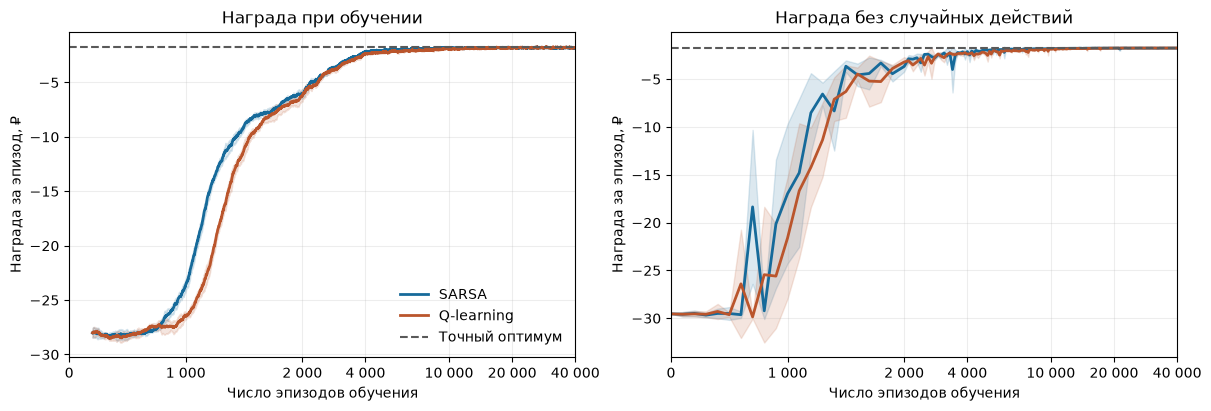

In [4]:
WINDOW = 200
COLORS = {"SARSA": "#166A9A", "Q-learning": "#BA552C"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for method, runs in results.items():
    training_rewards = np.stack([rewards for _, rewards, _ in runs])
    moving_rewards = np.stack([
        np.convolve(rewards, np.full(WINDOW, 1 / WINDOW), mode="valid")
        for rewards in training_rewards
    ])
    eval_rewards = np.stack([checks[:, 0] for _, _, checks in runs])

    for ax, episodes, curves in zip(
        axes, (np.arange(WINDOW, EPISODES + 1), EVAL_EPISODES), (moving_rewards, eval_rewards)
    ):
        mean, spread = curves.mean(axis=0), curves.std(axis=0)
        ax.plot(episodes, mean, label=method, color=COLORS[method], linewidth=2)
        ax.fill_between(episodes, mean - spread, mean + spread, color=COLORS[method], alpha=0.15)

for ax, title in zip(axes, ("Награда при обучении", "Награда без случайных действий")):
    ax.axhline(OPTIMAL_MEAN_REWARD, linestyle="--", color="0.35", label="Точный оптимум")
    ax.set(title=title, xlabel="Число эпизодов обучения", ylabel="Награда за эпизод, ₽")
    ax.set_xscale("symlog", linthresh=2_000)
    ax.set_xticks([0, 1_000, 2_000, 4_000, 10_000, 20_000, 40_000],
                  labels=["0", "1 000", "2 000", "4 000", "10 000", "20 000", "40 000"])
    ax.set_xlim(0, EPISODES)
    ax.grid(alpha=0.22)
axes[0].legend(loc="lower right", frameon=False)
plt.show()

In [5]:
lines = [
    f"| Метод | Награда при обучении, первые {DECAY_EPISODES} эп., ₽ | Итоговая награда, ₽ |"
    " Успех, % | Оптимальные решения, % | Запуски с точным оптимумом на всех стартах |",
    "|---|---:|---:|---:|---:|---:|",
]
for method, runs in results.items():
    early = np.stack([rewards[:DECAY_EPISODES] for _, rewards, _ in runs]).mean()
    final = np.stack([checks[-1] for _, _, checks in runs])
    reward, success, optimal = final.mean(axis=0)
    reached = np.count_nonzero(final[:, 2] == 1.0)
    lines.append(
        f"| {method} | {early:.3f} | {reward:.3f} | {100 * success:.2f} | {100 * optimal:.2f} "
        f"| {reached}/{len(SEEDS)} |"
    )

display(Markdown("\n".join(lines)))

| Метод | Награда при обучении, первые 4000 эп., ₽ | Итоговая награда, ₽ | Успех, % | Оптимальные решения, % | Запуски с точным оптимумом на всех стартах |
|---|---:|---:|---:|---:|---:|
| SARSA | -10.768 | -1.752 | 100.00 | 99.03 | 1/5 |
| Q-learning | -11.633 | -1.742 | 100.00 | 100.00 | 5/5 |

**При заданном бюджете Q-learning лучше для итоговой жадной стратегии.** Оба метода достигли цели на всех стартах. Q-learning использовал минимальное число подъёмов на каждом старте во всех пяти запусках. У SARSA доля оптимальных решений в среднем составила 99,03%.

В первые 4000 эпизодов SARSA тратил в среднем меньше подъёмов за эпизод. При высоком $\varepsilon$ его цель обновления учитывает, что следующим может оказаться случайное и затратное переливание. Q-learning на каждом обновлении ориентируется на лучшее доступное продолжение, что соответствует итоговой проверке без случайных действий. Результат сравнения относится к выбранной среде, параметрам и бюджету обучения.

## 5. Живая демонстрация

Нажмите ▶ или перетаскивайте ползунок под рисунком. Верхняя строка показывает разлив в два стакана за один подъём. В нижней строке начальный расклад требует минимум трёх подъёмов. Каждый кадр строится по состоянию после шага Gymnasium. Стакан, который подняли на этом шаге, выделен оранжевым.

In [6]:
DEMO_CASES = ((5, 3, 2, 2), (4, 4, 4, 0))
DEMO_RUN = 0  # Один и тот же seed для обоих методов.


def rollout(q, volumes):
    env = make_env(render_mode="ansi")
    policy = greedy_policy(q)
    observation, info = env.reset(options={"volumes": volumes})
    minimum = int(OPTIMAL_LIFTS[info["state_id"]])
    frames = [(observation, None, "Начальный расклад", 0.0, env.render())]
    total_reward = 0.0
    terminated = info["state_id"] == GOAL_ID
    truncated = False

    while not (terminated or truncated):
        action = policy[info["state_id"]]
        source, portions = ACTIONS[action]
        pours = ", ".join(f"№{i + 1} — {amount * UNIT_ML} мл" for i, amount in portions if amount)
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        frames.append((observation, source, f"Из №{source + 1} в {pours}", total_reward, env.render()))

    env.close()
    return frames, minimum, terminated


demos = {}
for volumes in DEMO_CASES:
    print(f"Старт, мл: {tuple(volume * UNIT_ML for volume in volumes)}")
    for method in METHODS:
        frames, minimum, solved = rollout(results[method][DEMO_RUN][0], volumes)
        demos[volumes, method] = frames, minimum, solved
        outcome = "цель достигнута" if solved else "предел шагов"
        print(f"  {method}, {outcome}, подъёмов: {len(frames) - 1}, минимум: {minimum}")
        for step, (_, _, description, total_reward, rendered) in enumerate(frames[1:], 1):
            print(f"    {step}. {description}  →  {rendered}  ({total_reward:g} ₽)")

Старт, мл: (250, 150, 100, 100)
  SARSA, цель достигнута, подъёмов: 1, минимум: 1
    1. Из №1 в №3 — 50 мл, №4 — 50 мл  →  150 мл  |  150 мл  |  150 мл  |  150 мл  (-1 ₽)
  Q-learning, цель достигнута, подъёмов: 1, минимум: 1
    1. Из №1 в №3 — 50 мл, №4 — 50 мл  →  150 мл  |  150 мл  |  150 мл  |  150 мл  (-1 ₽)
Старт, мл: (200, 200, 200, 0)
  SARSA, цель достигнута, подъёмов: 3, минимум: 3
    1. Из №1 в №2 — 50 мл  →  150 мл  |  250 мл  |  200 мл  |  0 мл  (-1 ₽)
    2. Из №2 в №3 — 50 мл, №4 — 50 мл  →  150 мл  |  150 мл  |  250 мл  |  50 мл  (-2 ₽)
    3. Из №3 в №4 — 100 мл  →  150 мл  |  150 мл  |  150 мл  |  150 мл  (-3 ₽)
  Q-learning, цель достигнута, подъёмов: 3, минимум: 3
    1. Из №1 в №2 — 50 мл, №4 — 50 мл  →  100 мл  |  250 мл  |  200 мл  |  50 мл  (-1 ₽)
    2. Из №2 в №1 — 50 мл, №3 — 50 мл, №4 — 100 мл  →  150 мл  |  50 мл  |  250 мл  |  150 мл  (-2 ₽)
    3. Из №3 в №2 — 100 мл  →  150 мл  |  150 мл  |  150 мл  |  150 мл  (-3 ₽)


In [7]:
fig, axes = plt.subplots(len(DEMO_CASES), len(METHODS), figsize=(10, 6.2), squeeze=False)
fig.subplots_adjust(left=0.09, right=0.98, bottom=0.10, top=0.90, wspace=0.27, hspace=0.90)
positions = np.arange(1, GLASSES + 1)
capacity_ml = CAPACITY * UNIT_ML


def draw_frame(step):
    for row, volumes in enumerate(DEMO_CASES):
        for column, method in enumerate(METHODS):
            ax = axes[row, column]
            frames, minimum, solved = demos[volumes, method]
            current = min(step, len(frames) - 1)
            observation, source, description, reward, _ = frames[current]
            volume_ml = observation * UNIT_ML
            active_glass = np.arange(GLASSES) == source
            colors = np.where(active_glass, "#D46D34", "#3485AD")

            ax.clear()
            ax.bar(positions, capacity_ml, width=0.56, color="#EEF3F7", zorder=1)
            ax.bar(positions, volume_ml, width=0.56, color=colors, zorder=2)
            ax.bar(positions, capacity_ml, width=0.56, fill=False, edgecolor="#566D7A", zorder=4)
            ax.axhline(TARGET * UNIT_ML, color="#202B31", linestyle="--", linewidth=1, zorder=3)
            for position, volume in zip(positions, volume_ml):
                ax.text(position, volume + 9, str(volume), ha="center", fontsize=9, zorder=5)

            finished = current == len(frames) - 1
            status = " · цель достигнута" if finished and solved else ""
            if finished and not solved:
                status = " · предел шагов"
            ax.set(
                xticks=positions, xticklabels=[f"№{i}" for i in positions],
                ylim=(0, capacity_ml + 32), yticks=np.arange(0, capacity_ml + 1, UNIT_ML),
                ylabel="мл", title=f"{method} · подъём {current} · {reward:g} ₽{status}",
            )
            ax.text(0.5, -0.22, f"{description} · минимум {minimum}",
                    transform=ax.transAxes, ha="center", fontsize=9)
            ax.spines[["top", "right"]].set_visible(False)


animation = FuncAnimation(
    fig, draw_frame, frames=max(len(frames) for frames, _, _ in demos.values()), interval=1100,
)
plt.close(fig)
# Текстовые значки доступны и без загрузки внешнего шрифта.
animation_html = animation.to_jshtml(default_mode="once")
button_icons = {
    "minus": "−", "fast-backward": "⏮", "step-backward": "◀|",
    "play fa-flip-horizontal": "◀", "pause": "⏸", "play": "▶",
    "step-forward": "|▶", "fast-forward": "⏭", "plus": "+",
}
for icon, label in button_icons.items():
    animation_html = animation_html.replace(f'<i class="fa fa-{icon}"></i>', label)
animation_html = animation_html[animation_html.index("<script"):]
display(HTML(animation_html))